### Import necessary packages

In [1]:
# imports for analysis
import muspan as ms
import numpy as np

# imports to make plots pretty
import seaborn as sns
sns.set_theme(style='white',font_scale=2)
sns.set_style('ticks')
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
mpl.rcParams['figure.dpi'] = 150 # set the resolution of the figure
np.random.seed(42) # Fixed seed for reproducibility

import os

### Define directories

In [ ]:
saved_domains_directory = r".\Template_Generated-Domains"

saved_domains_with_network_directory = r".\Template_Domains-with-Network"
save_count_arrays_directory = r".\Template_Count-Arrays"

if not os.path.exists(saved_domains_with_network_directory):
    os.makedirs(saved_domains_with_network_directory)
if not os.path.exists(save_count_arrays_directory):
    os.makedirs(save_count_arrays_directory)

In [3]:
saved_domains = os.listdir(saved_domains_directory)

domains = []

for s_domain in saved_domains:
    domain = ms.io.load_domain(os.path.join(saved_domains_directory,s_domain))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_1.csv
Number of objects: 102475
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_2.csv
Number of objects: 415261
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_3.csv
Number of objects: 229275
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity'] 
Networks: [] 
Distance matrices: []


### Generate a proximity network

In [7]:
for domain in domains:
    qCells = ms.query.query(domain, ('Collection',), 'is', 'Cell centres') # Query the domain to get cell centres
    ms.networks.generate_network(
    domain,
    network_name='proximity_boundary',
    objects_as_nodes=qCells,
    network_type='Proximity',
    min_edge_distance=0,
    max_edge_distance=15 # Adjust max edge distance if desired
    )

    # optional: save domains with networks
    ms.io.save_domain(domain, path_to_save=saved_domains_with_network_directory, name_of_file=domain.name)
    

Domain test_data_1.csv saved successfully to .\Template_Domains-with-Network.
Domain test_data_2.csv saved successfully to .\Template_Domains-with-Network.
Domain test_data_3.csv saved successfully to .\Template_Domains-with-Network.


### Visualise the network, zoomed in

(-14500.0, -14100.0)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


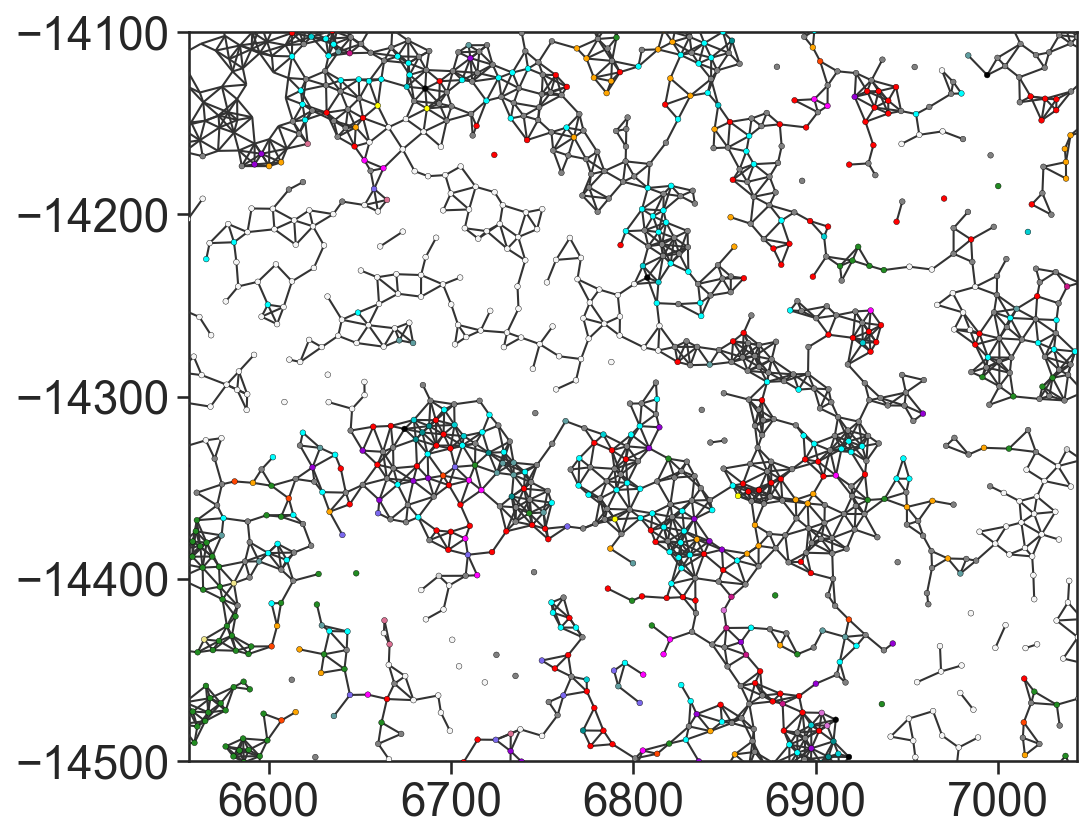

In [8]:
domain = domains[1]

# query cells from a specific ROI
qROI = ms.query.query(domain, ('label',"ROI"), 'is', 'ROI 1')

fig, ax = plt.subplots(figsize=(8, 6), nrows=1, ncols=1)

ms.visualise.visualise_network(
    domains[0],
    network_name='proximity_boundary',
    edge_weight_name=None,
    edge_cmap='Greys',
    edge_width=1,
    edge_vmin=0,
    edge_vmax=0.5,
    add_cbar=False,
    ax = ax,
    visualise_kwargs={
        'color_by': ('label', 'Phenotype'),
        'objects_to_plot': qROI,
        'add_cbar': False,
        'marker_size': 7.5,
        'shape_kwargs': {'alpha': 0.2, 'linewidth': 0.75},
        'scatter_kwargs': {'linewidth': 0.2, 'edgecolor': 'black'}
    }
)

x = 6800
y = -14300
r = 200
# Set the limits of the plot to zoom in on the point of interest
ax.set_xlim(x-r, x+r)
ax.set_ylim(y-r, y+r)

### Define clusters of interest and set colours

In [9]:
# Define the clusters of interest
short_version = ['CD8', 'FAP', 'PDPN', 'aSMA', 'panCK']

full_version = ['CD8', 'CD8_Other', 'PDPN_CD8', 'PDPN_CD8_Other',
                        'FAP', 'FAP_PDGFRa', 'FAP_PDGFRa_aSMA', 'FAP_PDPN',
                   'FAP_PDPN_PDGFRa', 'FAP_PDPN_PDGFRa_aSMA', 'FAP_PDPN_aSMA', 'FAP_aSMA',
                   'PDGFRa', 'PDGFRa_aSMA', 'PDPN', 'PDPN_PDGFRa', 'PDPN_PDGFRa_aSMA', 'PDPN_aSMA','aSMA',
                    'panCK', 'panCK_Other','FAP_PDPN_panCK','FAP_panCK', 'PDPN_panCK', 'PDPN_panCK_Other', 'Other',  'unclassified detections']

clusters_of_interest = short_version # full_version or short_versions
phenotype_colors = {
    'CD8' : 'cyan', 'CD8_Other': 'darkturquoise', 'PDPN_CD8' : 'cadetblue', 'PDPN_CD8_Other': 'darkcyan',
                        'FAP':'red', 'FAP_PDGFRa':'mediumvioletred', 'FAP_PDGFRa_aSMA':'violet', 'FAP_PDPN': 'darkviolet',
                   'FAP_PDPN_PDGFRa':'orchid', 'FAP_PDPN_PDGFRa_aSMA':'thistle', 'FAP_PDPN_aSMA':'mediumslateblue', 'FAP_aSMA': 'magenta',
                   'PDGFRa': 'yellow', 'PDGFRa_aSMA': 'khaki', 'PDPN': 'orange', 'PDPN_PDGFRa': 'gold', 'PDPN_PDGFRa_aSMA': 'goldenrod', 'PDPN_aSMA' : 'orangered','aSMA' : 'forestgreen',
                    'panCK' : 'whitesmoke', 'panCK_Other': 'lightgrey','FAP_PDPN_panCK': 'lavender','FAP_panCK': 'palevioletred', 'PDPN_panCK': 'peachpuff', 'PDPN_panCK_Other': 'wheat', 'Other': 'black',  'unclassified detections': 'grey'
}


# Update the domain with the new colors
for domain in domains:
    domain.update_colors(phenotype_colors, colors_to_update='labels', label_name='Phenotype')
    # optional: save domains with colour
    #ms.io.save_domain(domain, path_to_save= r"E:\Amy_muspan\muspanvenv\proximity\250714_COMB_domain_proximity", name_of_file= str(domain.name))

### Generate count arrays for each cluster of interest

The bolow piece of code will look through each cell of all celltypes in clusters_of_interest, find the cells that are 1 khop away in the proximity network and keep a counter of what type of cell those neighbouring cells are.

It saves the count arrays so they can be reloaded later

In [10]:
for domain in domains:
    labels, object_indices = ms.query.get_labels(domain, 'Phenotype')
    this_order_degree = {}
    total_contacts = np.zeros((len(clusters_of_interest), len(clusters_of_interest)))
    for idex, id in enumerate(clusters_of_interest):
    # Query the domain for the current cluster
        this_id_query = ms.query.query(domain, ('label', 'Phenotype'), 'is', id)
        
        try:
    # Generate k-hop neighbourhoods for the current cluster
            khop_neighbourhoods_prox = ms.networks.khop_neighbourhood(domain, network_name='proximity_boundary', source_objects=this_id_query, k=1)

    # Initialize a list to store the degrees
            these_degrees = []

    # Calculate the degree for each k-hop neighbourhood
            for k in khop_neighbourhoods_prox:
                these_degrees.append(len(khop_neighbourhoods_prox[k]))

    # Store the degrees in the dictionary
            this_order_degree[id] = these_degrees

         # Initialize an array to store the compositions, that is, what phenotype the neighbouring cells having
            these_compositions = np.zeros((len(khop_neighbourhoods_prox), len(clusters_of_interest)))
        # Calculate the composition for each k-hop neighbourhood
            for kid, k in enumerate(khop_neighbourhoods_prox):
                this_neighbourhood = khop_neighbourhoods_prox[k]
                for n in this_neighbourhood:
                    this_label_index = np.where(object_indices == n)[0][0]
                    if labels[this_label_index] in clusters_of_interest:
                        these_compositions[kid, clusters_of_interest.index(labels[this_label_index])] += 1
        # Calculate the average composition for the current cluster
            total_contacts[idex, :] = np.sum(these_compositions, axis=0)

        except:
            total_contacts[idex, :] = np.zeros((1, len(clusters_of_interest)))    
    #save the total_contacts array for each domain
    np.savetxt(os.path.join(save_count_arrays_directory, domain.name + "_array"),
                            total_contacts, fmt = '%d')

### Load in the saved count arrays

In [11]:
list_of_arrays = []

for filename in os.listdir(save_count_arrays_directory):
    cur_array = np.loadtxt(os.path.join(save_count_arrays_directory, filename), dtype=int)
    list_of_arrays.append(cur_array)

total_array = np.sum(list_of_arrays, axis=0)

print(total_array)

[[ 14929   2140   4144   1195   4968]
 [  2140  15528   3113   1115   1768]
 [  4144   3113 819010  18070  32682]
 [  1195   1115  18070 187734   5464]
 [  4968   1768  32682   5464 841707]]


### Normalise the array

In [17]:
norm_array = np.zeros((len(clusters_of_interest), len(clusters_of_interest)))

for i in range(len(clusters_of_interest)):
    norm_array[i,:] = total_array[i, :] / np.sum(total_array[i, :])


print(norm_array)

[[0.54533168 0.07817066 0.15137347 0.04365137 0.18147282]
 [0.09043272 0.65618661 0.13155003 0.04711799 0.07471264]
 [0.0047251  0.00354952 0.93385662 0.02060389 0.03726487]
 [0.00559515 0.00522058 0.08460609 0.87899503 0.02558316]
 [0.0056035  0.00199416 0.03686263 0.00616295 0.94937677]]


### Plot

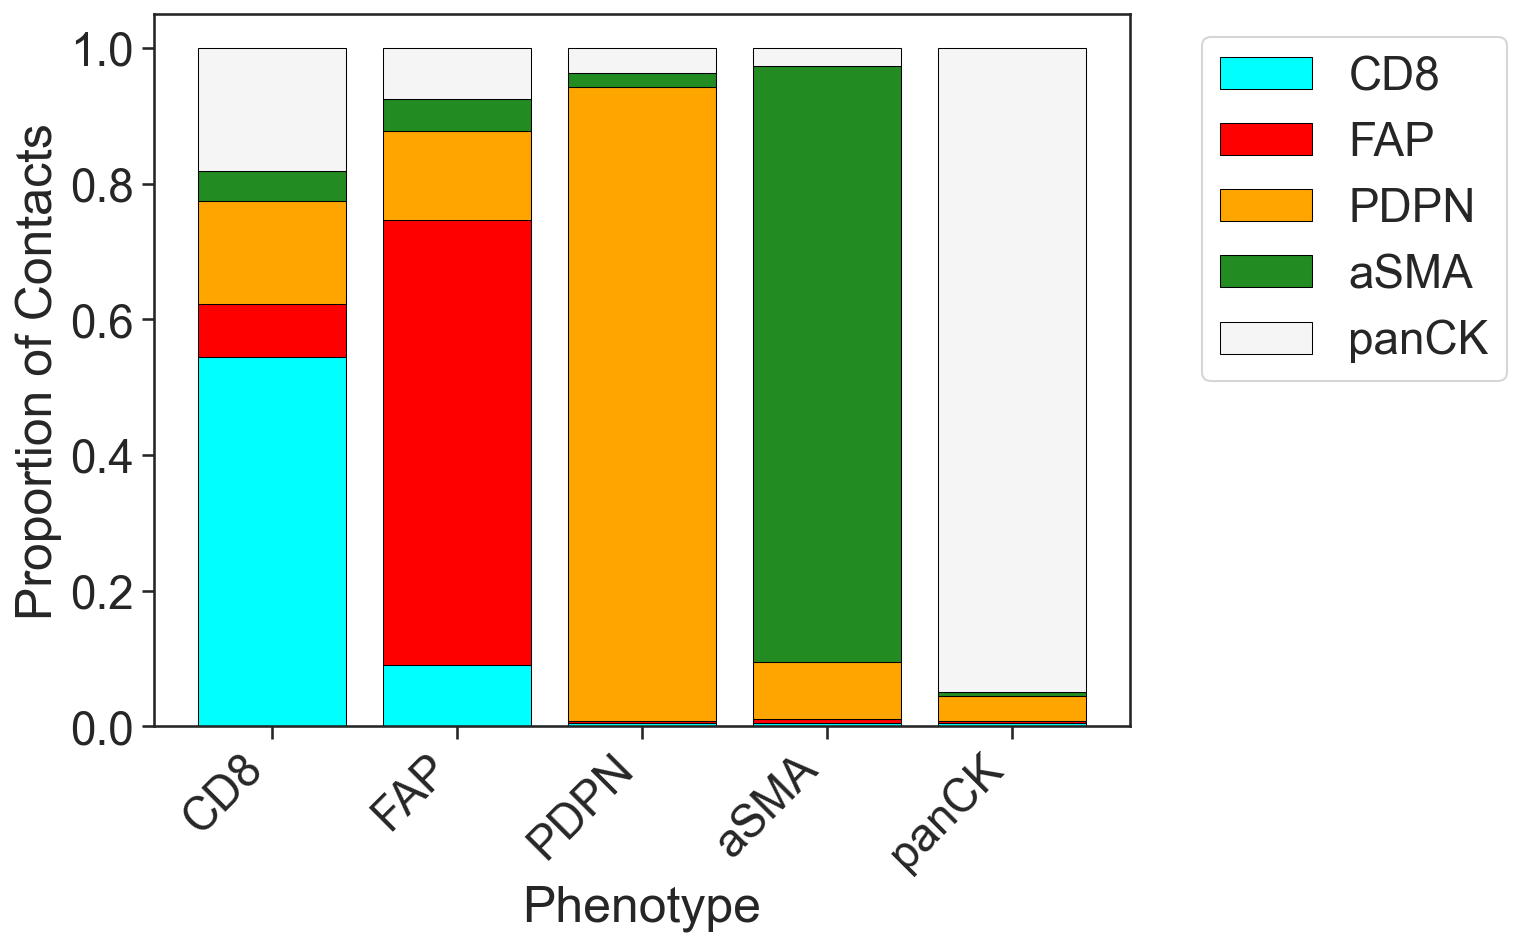

In [23]:
# Set the theme for seaborn plots
sns.set_theme(style='white', font_scale=2)
sns.set_style('ticks')

# Create a figure with two subplots

fig2, ax2 = plt.subplots(figsize=(8, 6))
fig2.tight_layout()


# Plot the stacked bar plot for each cluster
for i, cluster in enumerate(clusters_of_interest):
    ax2.bar(clusters_of_interest, norm_array[:, i], 
            label= cluster, bottom=np.sum(norm_array[:, :i], axis=1), 
            color=phenotype_colors[cluster],
            edgecolor = "black",
            linewidth = 0.5)

# Set x-axis and y-axis labels for the stacked bar plot
ax2.set_xlabel('Phenotype')
ax2.set_ylabel('Proportion of Contacts')

# Set x-axis labels for the stacked bar plot
ax2.set_xticklabels(clusters_of_interest, rotation=45, ha='right')

# Add legend to the stacked bar plot
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Show the plot
plt.show()